# 04. Solar model

**Part 1. Analysis**
1. Solar power over the day, one curve per day

**Part 2. Model**
2. Basic solar model: one sinusoid over the day, then the final parameters

**Part 3. Prediction**
3. The fixed model (same curve every day) compared with the measured solar power

**Part 4. Irradiance → power**
4. Convert irradiance (W/m², e.g. from a weather forecast) into solar power (W)

battery3 = solar. Solar only comes over Starlink (`direct`), so there's only data while Starlink is on (14 Jul 07:43 to 27 Jul 02:05).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, solar in
df["day"] = df.t.dt.floor("D")
df["hour"] = (df.t - df.day).dt.total_seconds() / 3600           # hour of day, UTC
solar = df.dropna(subset=["P_solar"])

def daily_axis(ax, start=pd.Timestamp("2025-07-14", tz="UTC"), end=pd.Timestamp("2025-07-28", tz="UTC")):
    ax.set_xlim(start, end)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
solar.groupby(solar.day.dt.strftime("%d %b")).P_solar.agg(["size", "min", "median", "max"]).round(1)

,size,min,median,max
day,,,,
14 Jul,9775,0.0,79.9,226.6
15 Jul,1574,0.0,120.3,205.9
16 Jul,1594,0.0,22.6,256.7
17 Jul,572,0.0,16.8,90.6
18 Jul,609,0.0,50.6,221.7
19 Jul,583,0.0,44.8,178.9
20 Jul,856,0.0,19.9,170.0
21 Jul,658,0.0,15.6,127.0
22 Jul,766,0.0,34.7,195.6


# Part 1. Analysis

## 1. Solar power over the day, every day on one plot

X = hour of day (UTC), y = solar power (V × I on battery3). One colour per day, from early (dark) to late (yellow). Every row with a solar value is plotted. Lines are broken wherever there's more than 5 min between rows (Starlink off), so they never bridge a gap.

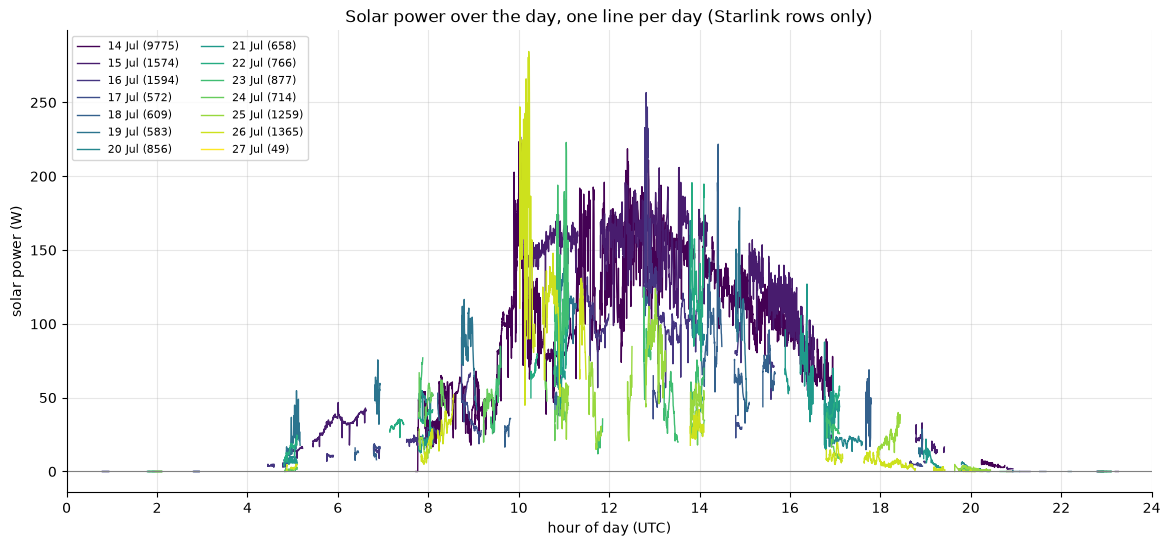

In [2]:
days = sorted(solar.day.unique())
colors = plt.cm.viridis(np.linspace(0, 1, len(days)))
fig, ax = plt.subplots()
for day, color in zip(days, colors):
    d = solar[solar.day == day]
    gap = np.flatnonzero((d.t.diff() > pd.Timedelta("5min")).values)
    x_b = np.insert(d.hour.values, gap, np.nan)       # a NaN before every gap breaks the line there
    y_b = np.insert(d.P_solar.values, gap, np.nan)
    ax.plot(x_b, y_b, "-", lw=1, color=color, label=f"{pd.Timestamp(day):%d %b} ({len(d)})")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("solar power (W)")
ax.set_title("Solar power over the day, one line per day (Starlink rows only)")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.show()

# Part 2. Model

## 2. Model: basic solar model: P(t) = A + B·cos(ωt) + C·sin(ωt)

t = hour of day (UTC), ω = 2π / 24 h. That's a sinusoid with a 24 h period. It's linear in A, B and C, so ordinary least squares solves it (`np.linalg.lstsq`).

The same curve can be written as **P(t) = A + R·cos(ω(t − t_peak))**, with amplitude R = √(B² + C²) and peak hour t_peak = atan2(C, B) / ω. Those two are easier to read, so they're printed too.

**One point per minute:** Starlink sent every 1 s on 14 Jul and every 15 s on other days, so 14 Jul has about half of all solar rows. Fitting raw rows would mostly fit 14 Jul. Instead, solar power is averaged per minute and each minute counts once. All minutes are kept, day and night, every day.

,value,std error
A (W),35.70,0.74
B (W),-67.06,1.02
C (W),-9.32,0.94


amplitude R = 67.7 W, peak at 12.53 h UTC, max = A + R = 103.4 W, min = A − R = -32.0 W
n = 2905 minutes, R² = 0.597, residual std = 34.7 W


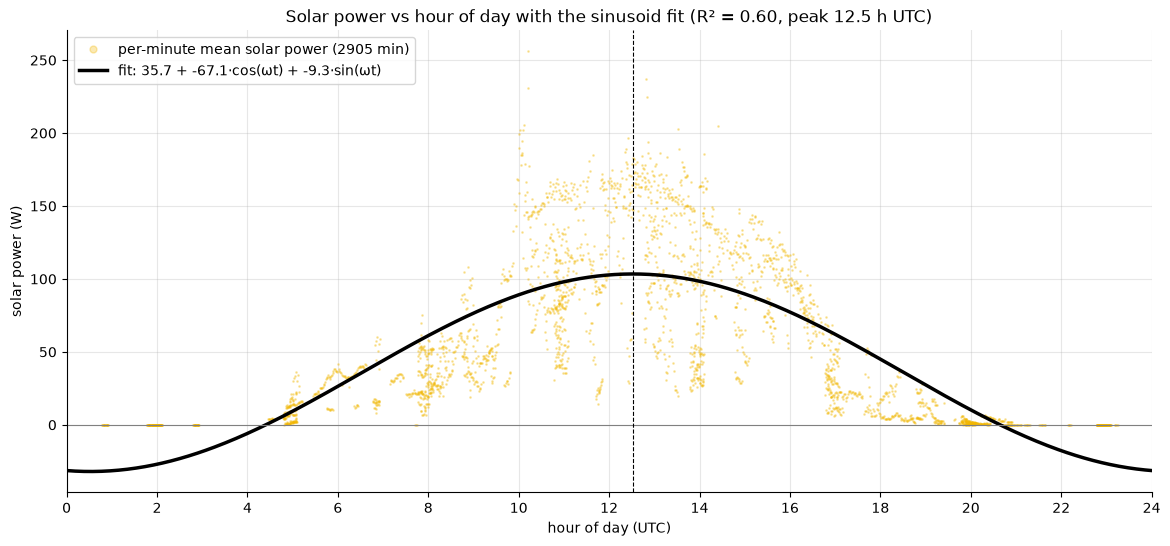

In [3]:
OMEGA = 2 * np.pi / 24
sm = solar.set_index("t").P_solar.resample("1min").mean().dropna().to_frame()
sm["hour"] = (sm.index - sm.index.floor("D")).total_seconds() / 3600

X = np.column_stack([np.ones(len(sm)), np.cos(OMEGA * sm.hour), np.sin(OMEGA * sm.hour)])
y = sm.P_solar.values
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ coef
r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * (resid ** 2).sum() / (len(y) - X.shape[1]))
A, B, C = coef
R = np.hypot(B, C)
t_peak = (np.arctan2(C, B) / OMEGA) % 24
display(pd.DataFrame({"value": coef, "std error": se}, index=["A (W)", "B (W)", "C (W)"]).round(2))
print(f"amplitude R = {R:.1f} W, peak at {t_peak:.2f} h UTC, max = A + R = {A + R:.1f} W, min = A − R = {A - R:.1f} W")
print(f"n = {len(y)} minutes, R² = {r2:.3f}, residual std = {resid.std():.1f} W")

fig, ax = plt.subplots()
ax.plot(sm.hour, sm.P_solar, ".", ms=2, alpha=0.3, color="#f2b701", label=f"per-minute mean solar power ({len(sm)} min)")
h = np.linspace(0, 24, 500)
ax.plot(h, A + B * np.cos(OMEGA * h) + C * np.sin(OMEGA * h), lw=2.5, color="k",
        label=f"fit: {A:.1f} + {B:.1f}·cos(ωt) + {C:.1f}·sin(ωt)")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(t_peak, color="k", lw=0.8, ls="--")
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("solar power (W)")
ax.set_title(f"Solar power vs hour of day with the sinusoid fit (R² = {r2:.2f}, peak {t_peak:.1f} h UTC)")
ax.legend(markerscale=5, loc="upper left")
plt.show()

### Final parameters

**P_solar(t) = max(0, A + B·cos(ωt) + C·sin(ωt))**, ω = 2π/24 h, t = UTC hour. Clipped at 0 because the raw curve goes negative at night; this clipped version is what nb 05 uses.

Known limits: the same curve every day (no clouds, no day-to-day change), a 24 h period for a ~16 h day, and it's an average over cloudy and clear minutes, not a clear-sky curve.

In [4]:
pd.DataFrame([
    ["A", f"{A:.1f} ± {se[0]:.1f} W", "mean level"],
    ["B", f"{B:.1f} ± {se[1]:.1f} W", "cos term"],
    ["C", f"{C:.1f} ± {se[2]:.1f} W", "sin term"],
    ["amplitude", f"{R:.1f} W", "√(B² + C²)"],
    ["peak", f"{t_peak:.2f} h UTC", "atan2(C, B) / ω"],
    ["fit", f"R² = {r2:.2f}, residual std ≈ {resid.std():.0f} W", f"{len(y)} per-minute means"],
], columns=["parameter", "value", "note"]).set_index("parameter")

,value,note
parameter,,
A,35.7 ± 0.7 W,mean level
B,-67.1 ± 1.0 W,cos term
C,-9.3 ± 0.9 W,sin term
amplitude,67.7 W,√(B² + C²)
peak,12.53 h UTC,"atan2(C, B) / ω"
fit,"R² = 0.60, residual std ≈ 35 W",2905 per-minute means


# Part 3. Prediction

## 3. Prediction: fixed model vs measured solar

The model only knows the time of day, so it predicts **the same curve every day**. It is compared with the measured solar power (per-minute mean, Starlink minutes only, the only ones with solar). Error = actual − predicted.

In [5]:
def solar_model(hour):
    return np.clip(A + B * np.cos(OMEGA * hour) + C * np.sin(OMEGA * hour), 0, None)

sp = sm.copy()
sp["P_pred"] = solar_model(sp.hour)
sp["err"] = sp.P_solar - sp.P_pred
print(f"n = {len(sp)} minutes: mean error {sp.err.mean():+.1f} W, RMSE {np.sqrt((sp.err ** 2).mean()):.1f} W, "
      f"max |error| {sp.err.abs().max():.0f} W")

n = 2905 minutes: mean error -2.4 W, RMSE 33.8 W, max |error| 165 W


**Over the mission.** Top: measured solar (yellow dots, one per minute) and the model as a continuous line (black, also through the hours with no Starlink). Bottom: error = actual − predicted, only where there's a measurement.

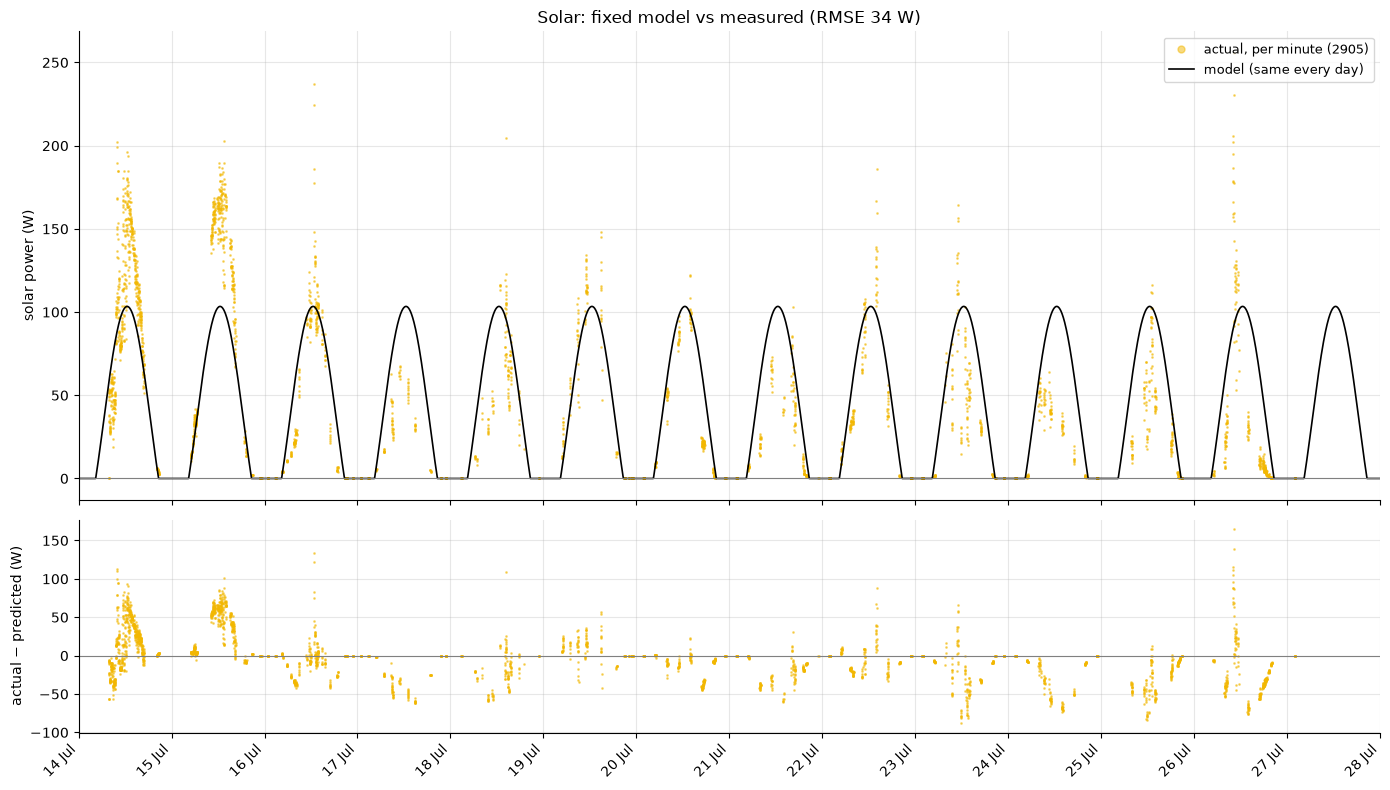

In [6]:
grid = pd.date_range("2025-07-14", "2025-07-28", freq="5min", tz="UTC")
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax.plot(sp.index, sp.P_solar, ".", ms=2, alpha=0.5, color="#f2b701", label=f"actual, per minute ({len(sp)})")
ax.plot(grid, solar_model((grid - grid.floor("D")).total_seconds() / 3600), "-", lw=1.2, color="k", label="model (same every day)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("solar power (W)")
ax.set_title(f"Solar: fixed model vs measured (RMSE {np.sqrt((sp.err ** 2).mean()):.0f} W)")
ax.legend(markerscale=5, loc="upper right", fontsize=9)
ax2.plot(sp.index, sp.err, ".", ms=2, alpha=0.5, color="#f2b701")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("actual − predicted (W)")
daily_axis(ax2)
plt.tight_layout(); plt.show()

**Per day:** mean measured vs mean predicted solar over the minutes with data. Days with few minutes or minutes only at some hours are not comparable with each other.

In [7]:
g = sp.groupby(sp.index.floor("D"))
daily = g.agg(minutes=("err", "size"), actual_W=("P_solar", "mean"), predicted_W=("P_pred", "mean"), mean_error_W=("err", "mean"))
daily["RMSE_W"] = g.err.apply(lambda e: np.sqrt((e ** 2).mean()))
daily.set_axis(daily.index.strftime("%d %b")).round(1).T

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul
minutes,573.0,407.0,271.0,115.0,122.0,133.0,191.0,153.0,171.0,184.0,152.0,180.0,244.0,9.0
actual_W,98.6,106.1,55.2,22.5,56.0,56.0,30.5,26.5,43.1,36.6,21.8,32.8,37.5,0.0
predicted_W,83.5,70.5,62.7,47.8,74.4,48.1,43.9,45.6,48.1,56.6,47.5,60.5,58.9,0.0
mean_error_W,15.1,35.6,-7.5,-25.3,-18.4,7.9,-13.4,-19.1,-5.0,-20.0,-25.7,-27.7,-21.4,0.0
RMSE_W,35.0,44.8,23.4,33.5,30.5,17.3,20.5,25.5,18.8,34.9,35.8,35.7,44.1,0.0


# Part 4. Irradiance → power

## 4. From irradiance (W/m²) to solar power (W)

Weather models (ERA5, Open-Meteo forecasts, see `sim/compare_weather.py`) give **irradiance G** in W/m² (`shortwave_radiation` = global horizontal). To turn it into power:

**P_solar = η · A · G**

- A = panel area (m²)
- η = everything from sunlight to battery: cell efficiency, tilt/heading, dirt/spray, MPPT and wiring losses

We can't separate η and A from this data, so we treat **k = η · A** (m², "effective area") as one number. **Assumption:** ERA5 for July 2025 at the nominal position (60.5° N, 1.5° E) is a realistic July for the North Sea. Positions and dates are shifted, so ERA5 won't match the day-by-day weather the boat actually had. We only compare averages.

We estimate k two ways:
- **Average day:** k = measured Wh/day ÷ ERA5 Wh/m²/day, both taken as the mean over the day by UTC hour.
- **Peak:** k = highest measured hourly mean ÷ highest ERA5 hourly value in July (the best hour in each).

In [8]:
from pathlib import Path
import json, urllib.parse, urllib.request

ERA5_FILE = Path("../data/era5_irradiance_2025-07.csv")
if not ERA5_FILE.exists():   # fetch once from Open-Meteo, then reuse the file
    q = {"latitude": 60.5, "longitude": 1.5, "start_date": "2025-07-01", "end_date": "2025-07-31",
         "hourly": "shortwave_radiation", "models": "era5", "timezone": "UTC"}
    with urllib.request.urlopen("https://archive-api.open-meteo.com/v1/archive?" + urllib.parse.urlencode(q), timeout=30) as r:
        h = json.load(r)["hourly"]
    pd.DataFrame({"t": h["time"], "G": h["shortwave_radiation"]}).to_csv(ERA5_FILE, index=False)
era5 = pd.read_csv(ERA5_FILE)
era5["t"] = pd.to_datetime(era5.t, utc=True)
era5 = era5.set_index("t").G        # W/m², mean over the hour BEFORE the timestamp

# hour-of-day profiles (UTC); ERA5 value at hh:00 covers hh-1 → hh, so it goes in bin hh-1
G_by_hour = era5.groupby((era5.index - pd.Timedelta("1h")).hour).mean()
P_by_hour = sm.groupby(sm.index.hour).P_solar.mean().reindex(range(24)).fillna(0)   # missing hour (03 UTC) = night = 0

E_meas = P_by_hour.sum()                       # Wh/day
E_irr = G_by_hour.sum()                        # Wh/m²/day
k_avg = E_meas / E_irr
P_hourly = sm.P_solar.resample("1h").mean()
k_peak = P_hourly.max() / era5.max()

pd.DataFrame([
    ["average day", f"{E_meas:.0f} Wh/day", f"{E_irr:.0f} Wh/m²/day", f"{k_avg:.3f} m²"],
    ["peak hour", f"{P_hourly.max():.0f} W", f"{era5.max():.0f} W/m²", f"{k_peak:.3f} m²"],
], columns=["method", "measured solar", "ERA5 irradiance", "k = η·A"]).set_index("method")

,measured solar,ERA5 irradiance,k = η·A
method,,,
average day,940 Wh/day,5724 Wh/m²/day,0.164 m²
peak hour,164 W,783 W/m²,0.210 m²


**Average day by hour.** Measured solar per UTC hour (mean of all per-minute means in that hour, all days) against ERA5 July irradiance × k. Left axis is power (W). ERA5 × k_avg is the average-day estimate; ERA5 × k_peak is the same irradiance scaled with the peak estimate.

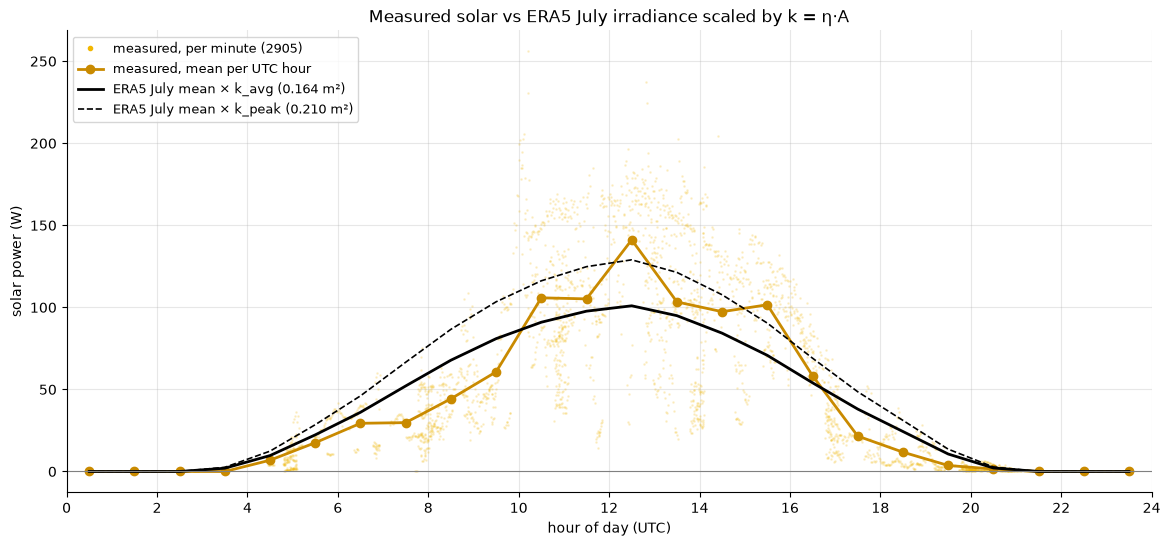

In [9]:
hrs = np.arange(24) + 0.5
fig, ax = plt.subplots()
ax.plot(sm.hour, sm.P_solar, ".", ms=2, alpha=0.15, color="#f2b701", label=f"measured, per minute ({len(sm)})")
ax.plot(hrs, P_by_hour, "o-", color="#c98a00", lw=2, label="measured, mean per UTC hour")
ax.plot(hrs, k_avg * G_by_hour, "-", color="k", lw=2, label=f"ERA5 July mean × k_avg ({k_avg:.3f} m²)")
ax.plot(hrs, k_peak * G_by_hour, "--", color="k", lw=1.2, label=f"ERA5 July mean × k_peak ({k_peak:.3f} m²)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("solar power (W)")
ax.set_title("Measured solar vs ERA5 July irradiance scaled by k = η·A")
leg = ax.legend(loc="upper left", fontsize=9)
leg.legend_handles[0].set_markersize(6); leg.legend_handles[0].set_alpha(1)
plt.show()